In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metric import evaluate_metrics

In [2]:
TRAIN_IMAGE = 'train-images.idx3-ubyte'
TRAIN_LABEL = 'train-labels.idx1-ubyte'
TEST_IMAGE = 't10k-images.idx3-ubyte'
TEST_LABEL = 't10k-labels.idx1-ubyte'

def load_images(filepath):
    with open(filepath, 'rb') as f:
        # Bỏ qua 16 bytes header (Magic number, number of images, rows, cols)
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    # Reshape về dạng (Số ảnh, 784 điểm ảnh)
    return data.reshape(-1, 28 * 28)

def load_labels(filepath):
    with open(filepath, 'rb') as f:
        # Bỏ qua 8 bytes header (Magic number, number of items)
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
    return data

X_train_raw = load_images(TRAIN_IMAGE)
y_train_raw = load_labels(TRAIN_LABEL)
X_test_raw = load_images(TEST_IMAGE)
y_test_raw = load_labels(TEST_LABEL)

X_train = X_train_raw[(y_train_raw == 0) | (y_train_raw == 1)] / 255.0 
y_train = y_train_raw[(y_train_raw == 0) | (y_train_raw == 1)]

X_test = X_test_raw[(y_test_raw == 0) | (y_test_raw == 1)] / 255.0 
y_test = y_test_raw[(y_test_raw == 0) | (y_test_raw == 1)]

print(f"Kích thước tập Train (chỉ gồm 0 & 1): {X_train.shape}")
print(f"Kích thước tập Test  (chỉ gồm 0 & 1): {X_test.shape}\n")


Kích thước tập Train (chỉ gồm 0 & 1): (12665, 784)
Kích thước tập Test  (chỉ gồm 0 & 1): (2115, 784)



In [3]:
def sigmoid(z):
    return 1/(1+np.exp(-z))


class LogisticRegresstion:
    def  __init__(self, learning_rate=0.1, iterations=1000):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.training_log = {
            "index": [],
            "loss": []
        }

    def train(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.random.rand(n_features)
        self.bias = np.random.random()

        for i in range(self.iterations):
            linear = X @ self.weights + self.bias
            y_predict = sigmoid(linear)
            gradient_w = 1/n_samples*X.T @ (y_predict - y)
            gradient_b = 1/n_samples * np.sum(y_predict - y)

            self.weights -= self.learning_rate*gradient_w
            self.bias -= self.learning_rate*gradient_b

            if((i+1)%100 == 0 or i==self.iterations-1 or i==0):
                loss = -np.mean(y*np.log(y_predict + 1e-10) + (1 - y)*np.log(1 - y_predict + 1e-10))
                self.training_log["index"].append(i)
                self.training_log["loss"].append(loss)
                print(f"{i}    {loss}")         

    def draw_loss(self):
        index = np.array(self.training_log["index"])
        loss = np.array(self.training_log["loss"])
        plt.figure(figsize=(6,4))
        plt.plot(index, loss)
        plt.tight_layout()
        plt.show()


    def predict_prob(self, X):
        linear= X @ self.weights + self.bias
        return sigmoid(linear)

    def predict(self, X, threshold=0.5):
        return (self.predict_prob(X) >= threshold).astype(int)


In [4]:
model = LogisticRegresstion(learning_rate=0.1, iterations=1000)
model.train(X=X_train, y=y_train)

print("\nTest nhanh\nDự đoán:",model.predict(X_test[0]), "Đáp án: ",y_test[0])

0    10.768223109364053
99    0.0612495100671256
199    0.03392876927283433
299    0.024843170753515626
399    0.020112563066710918
499    0.0172218172526977
599    0.015276759189394098
699    0.013870168287443634
799    0.012795720729062428
899    0.011939938473926026
999    0.011235944469535186

Test nhanh
Dự đoán: 1 Đáp án:  1


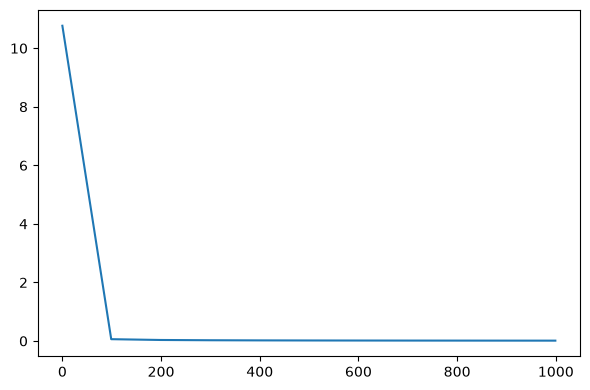

In [5]:
model.draw_loss()

In [7]:
y_pred = model.predict(X_test)
eval = evaluate_metrics(y_true=y_test.astype(int), y_pred=y_pred)
print(f"Precision: {eval["Precision"]:.4}")
print(f"Recall: {eval["Recall"]:.4f}")
print(f"F1_score: {eval["F1_macro"]:.4f}")

Precision: 0.9982
Recall: 0.9982
F1_score: 0.9982
